# Geodesic Maze Solver - Walkthrough

This notebook solves an image of a maze using classic **image processing** - no
graph is ever built by hand. It imports the reusable pipeline from
[`src/maze_solver.py`](../src/maze_solver.py) and shows what each step produces:

1. **Load & binarize** the picture into walls vs. free space, then crop to the maze.
2. **Seal** hairline wall gaps and the outer border - but only when that keeps the
   maze connected.
3. **Find** the coloured start/end markers and **flood fill** from each.
4. **Fast Marching** builds a *geodesic distance map* from the start.
5. **Steepest descent** traces the shortest path, which we then **centre** in the
   corridors and draw in red.

The geodesic-distance idea follows Cris Luengo's *"Solving mazes using image
analysis"*. All the heavy lifting lives in the library; here we just call it and
plot the results.

## Setup

Import the pipeline from the `src` package and pick an example maze.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import skfmm

# Find the repository root (the folder that contains src/maze_solver.py) so this
# notebook works whether it is run from the repo root or from notebooks/.
ROOT = Path.cwd()
while not (ROOT / "src" / "maze_solver.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.maze_solver import (
    load_image, binarize, crop_to_walls, seal_walls, seal_border,
    find_endpoints, flood_fill, geodesic_distance, trace_path,
    center_path, draw_solution, solve_maze_image,
)

MAZE_PATH = ROOT / "examples" / "maze_medium.png"
print("Solving:", MAZE_PATH.name)
%matplotlib inline

Solving: maze_medium.png


## The key idea - a geodesic distance map

Everything rests on one concept, shown here on a tiny example. A **geodesic
distance map** gives, for every free pixel, the length of the shortest route
*through the corridors* back to the start - the wave flows **around** walls,
never through them. Dark = close to the start, bright = far away. Two pixels that
look close on the page can be far apart in the maze when a wall forces a detour.
Because the value only grows away from the start, we can recover the path by
starting at the goal and always stepping toward a **smaller** value.

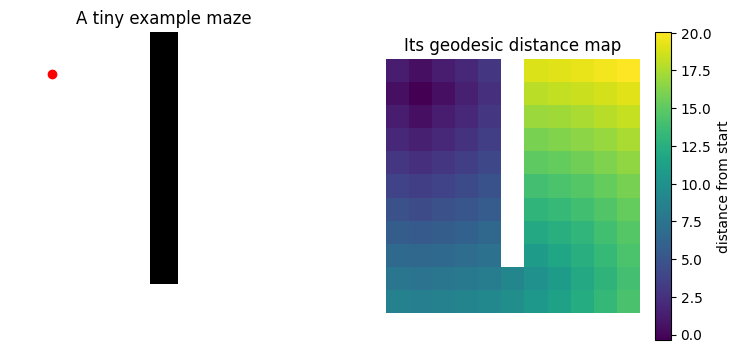

In [2]:
# A tiny example maze: a vertical wall with a gap at the bottom forces a detour.
example = np.ones((11, 11), dtype=bool)
example[0:9, 5] = False
example_start = (1, 1)

phi = np.ones(example.shape)
phi[example_start] = -1
phi = np.ma.MaskedArray(phi, mask=~example)
example_distance = skfmm.distance(phi)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(example, cmap="gray")
axes[0].plot(example_start[1], example_start[0], "ro")
axes[0].set_title("A tiny example maze")
axes[0].axis("off")
heat = axes[1].imshow(example_distance, cmap="viridis")
axes[1].set_title("Its geodesic distance map")
axes[1].axis("off")
fig.colorbar(heat, ax=axes[1], label="distance from start")
plt.show()

## Step 1 - Load & binarize

We read the image and split it into free space (bright) and walls (dark) with
**Otsu thresholding**, which picks the brightness cut-off automatically.

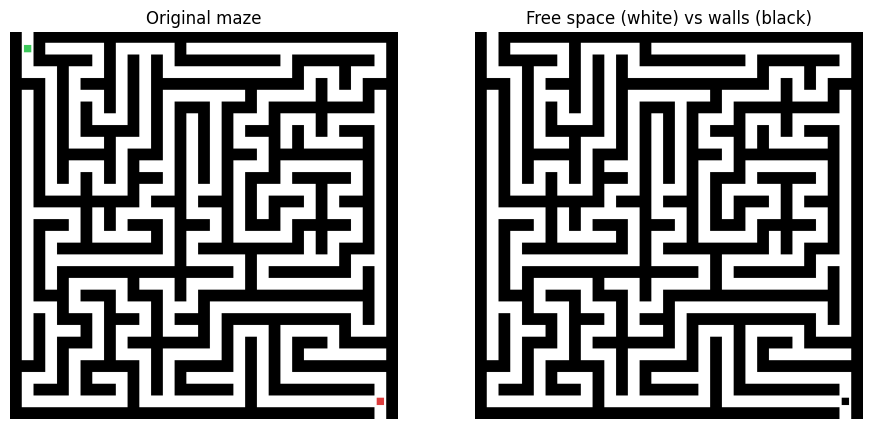

In [3]:
rgb = load_image(MAZE_PATH)
free_mask = binarize(rgb)

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
axes[0].imshow(rgb)
axes[0].set_title("Original maze")
axes[0].axis("off")
axes[1].imshow(free_mask, cmap="gray")
axes[1].set_title("Free space (white) vs walls (black)")
axes[1].axis("off")
plt.show()

## Step 2 - Crop and seal

We crop to the bounding box of the walls (removing the outside margin so the path
cannot cheat around the maze), then optionally seal hairline wall gaps and the
outer border. Each seal is applied **only if the maze stays connected** (the main
corridor network keeps at least 94% of its pixels), so a seal never cuts a real
corridor.

Wall-gap seal applied:  True
Border seal applied:    True


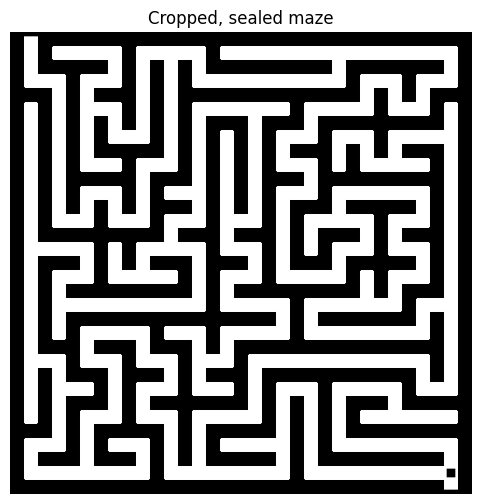

In [4]:
maze, offset = crop_to_walls(rgb, free_mask)
maze, sealed_walls = seal_walls(maze)
maze, sealed_border = seal_border(maze)
print("Wall-gap seal applied: ", sealed_walls)
print("Border seal applied:   ", sealed_border)

plt.figure(figsize=(6, 6))
plt.imshow(maze, cmap="gray")
plt.title("Cropped, sealed maze")
plt.axis("off")
plt.show()

## Step 3 - Find the markers & flood fill

The green marker is the start and the red marker is the end. We snap each to the
nearest pixel of the main corridor network, then **flood fill** from both using
4-connectivity. If both fills cover the same region, the maze is solvable.

Start: (23, 23)  End: (498, 503)
Start can reach end: True


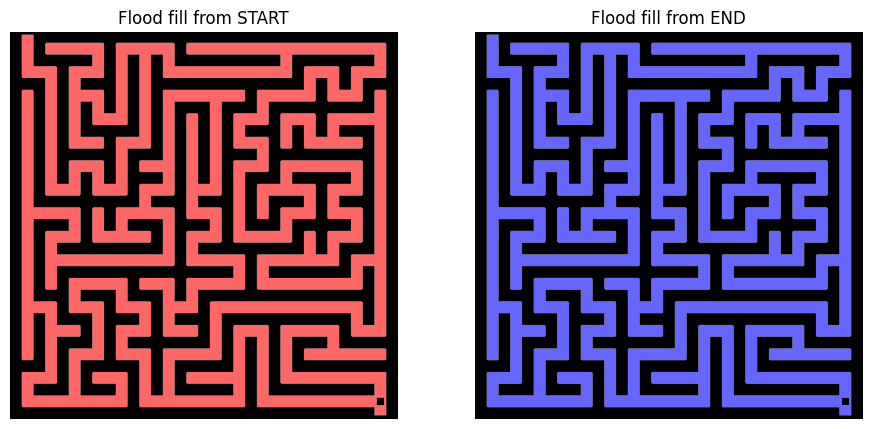

In [5]:
start_px, end_px = find_endpoints(rgb, maze, offset)
reach_start = flood_fill(maze, start_px)
reach_end = flood_fill(maze, end_px)
print("Start:", start_px, " End:", end_px)
print("Start can reach end:", bool(reach_start[end_px]))

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
axes[0].imshow(maze, cmap="gray")
axes[0].imshow(np.ma.masked_where(~reach_start, reach_start), cmap="autumn", alpha=0.6)
axes[0].set_title("Flood fill from START")
axes[0].axis("off")
axes[1].imshow(maze, cmap="gray")
axes[1].imshow(np.ma.masked_where(~reach_end, reach_end), cmap="winter", alpha=0.6)
axes[1].set_title("Flood fill from END")
axes[1].axis("off")
plt.show()

## Step 4 - Geodesic distance map

Fast Marching builds the geodesic distance from the start to every corridor
pixel. Dark is close to the start, bright is far - the values grow as we move
deeper into the maze.

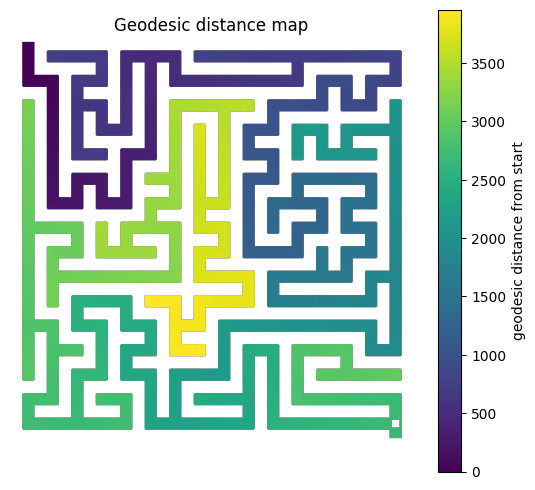

In [6]:
distance_map = geodesic_distance(maze, start_px)

plt.figure(figsize=(6.5, 6))
heat = plt.imshow(distance_map, cmap="viridis")
plt.colorbar(heat, label="geodesic distance from start")
plt.title("Geodesic distance map")
plt.axis("off")
plt.show()

## Step 5 - Trace, centre & draw

Starting at the end, we step to the lowest-distance neighbour until we reach the
start (orthogonal moves only, so the path never crosses a wall corner). We then
**centre** the path in the corridors and paint it red on the original image.

Reached the start: True  Path length: 3032 pixels


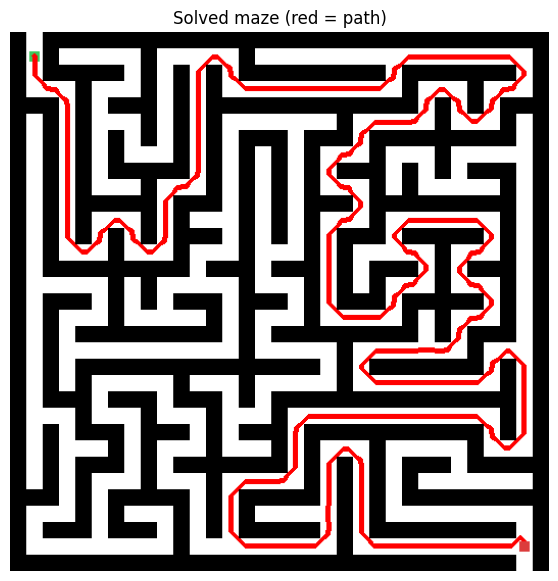

In [7]:
raw_path, reached = trace_path(distance_map, start_px, end_px)
path = center_path(raw_path, maze)
solution = draw_solution(rgb, maze, path, offset)
print("Reached the start:", reached, " Path length:", len(path), "pixels")

plt.figure(figsize=(7, 7))
plt.imshow(solution)
plt.title("Solved maze (red = path)")
plt.axis("off")
plt.show()

## All in one call

Everything above is wrapped in `solve_maze_image`, which the command-line tool
(`cli.py`) also uses. One call returns the solution and every intermediate
result.

Reached the start: True  Path length: 5398


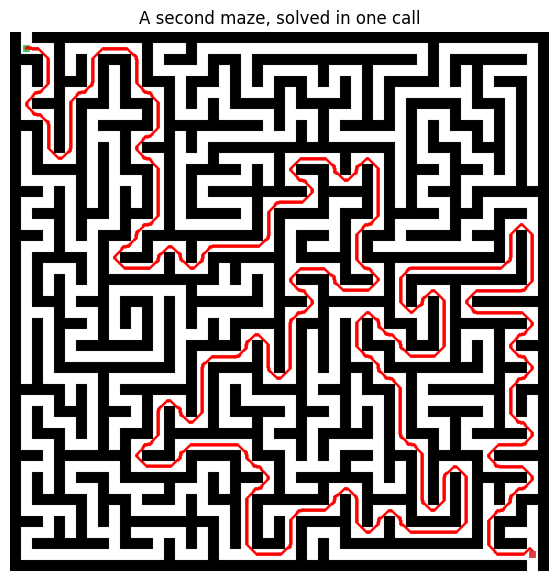

In [8]:
result = solve_maze_image(ROOT / "examples" / "maze_large.png")
print("Reached the start:", result.reached, " Path length:", len(result.path))

plt.figure(figsize=(7, 7))
plt.imshow(result.solution)
plt.title("A second maze, solved in one call")
plt.axis("off")
plt.show()

## References

- **Cris Luengo - "Solving mazes using image analysis"**:
  https://www.crisluengo.net/archives/277/ - the geodesic distance + steepest
  descent idea behind Steps 4 and 5.
- **scikit-fmm**: https://scikit-fmm.readthedocs.io/ - the Fast Marching Method.
- **scikit-image**: https://scikit-image.org/ - image I/O, Otsu thresholding,
  flood fill and morphology.